**Obesity Prediction**

The dataset include data for the estimation of obesity levels in individuals from the countries of Mexico, Peru and Colombia, based on their eating habits and physical condition. 23% of the data was collected directly from users through a survey conducted by Fabio Mendoza Palechor and Alexis de la Hoz Manotas in a web platform and 77% of the data was generated synthetically using the Weka tool and the SMOTE filter.



The data contains 19 attributes and 2111 records.
- **Gender**: 1 = male, 0 = female
- **Age**: Respondent’s age in years
- **family_history_with_overweight**: 1 = has/had an overweight family member, 0 = no
- **FAVC**: 1 = frequently eats high-calorie food, 0 = no
- **FCVC**: 1 = usually eats vegetables with meals, 0 = no
- **NCP**: Number of main meals per day: 0 = 1–2 meals, 1 = 3 meals, 2 = more than 3 meals
- **CAEC**: Amount of food eaten between meals, on a scale of 0–3
- **SMOKE**: 1 = smoker, 0 = non-smoker
- **CH2O**: Amount of water consumed, on a scale of 0–2
- **SCC**: 1 = monitors calorie intake, 0 = does not monitor
- **FAF**: Level of physical activity, on a scale of 0–3
- **TUE**: Time spent using devices with screens, on a scale of 0–2
- **CALC**: Frequency of alcohol consumption, on a scale of 0–3
- **Automobile**: 1 = primary transportation mode is automobile, 0 = otherwise
- **Bike**: 1 = primary transportation mode is bicycle, 0 = otherwise
- **Motorbike**: 1 = primary transportation mode is motorbike, 0 = otherwise
- **Public_Transportation**: 1 = primary transportation mode is public transportation, 0 = otherwise
- **Walking**: 1 = primary transportation mode is walking, 0 = otherwise
- **NObeyesdad**: 1 = obese, 0 = not obese

**Binary / Nominal:**
- Gender
- family_history_with_overweight
- FAVC
- SMOKE
- SCC
- Automobile
- Bike
- Motorbike
- Public_Transportation
- Walking
- Obese (target)

**Ordinal (after rounding the SMOTE decimals):**
- FCVC
- NCP
- CH2O
- FAF
- TUE
- CAEC
- CALC

**Continuous:**
- Age

https://www.kaggle.com/datasets/muhramasaputra/obesity-based-on-eating-habits-and-physical-cond/data

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

In [ ]:
# Load the dataset
import kagglehub

# Download latest version
path = kagglehub.dataset_download("muhramasaputra/obesity-based-on-eating-habits-and-physical-cond")

print("Path to dataset files:", path)

file_path = Path(path) / "obesity.csv"
obesity = pd.read_csv(file_path)

100%|██████████| 38.4k/38.4k [00:00<00:00, 20.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/muhramasaputra/obesity-based-on-eating-habits-and-physical-cond/versions/1


#### Initial Inspection

In [ ]:
obesity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   int64  
 1   Age                             2111 non-null   float64
 2   family_history_with_overweight  2111 non-null   int64  
 3   FAVC                            2111 non-null   int64  
 4   FCVC                            2111 non-null   float64
 5   NCP                             2111 non-null   float64
 6   CAEC                            2111 non-null   int64  
 7   SMOKE                           2111 non-null   int64  
 8   CH2O                            2111 non-null   float64
 9   SCC                             2111 non-null   int64  
 10  FAF                             2111 non-null   float64
 11  TUE                             2111 non-null   float64
 12  CALC                            21

In [ ]:
obesity.rename(columns={"NObeyesdad": "Obese"}, inplace=True)

In [ ]:
obesity.columns

Index(['Gender', 'Age', 'family_history_with_overweight', 'FAVC', 'FCVC',
       'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC',
       'Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking',
       'Obese'],
      dtype='object')

In [ ]:
obesity.head()

,Gender,Age,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,Automobile,Bike,Motorbike,Public_Transportation,Walking,Obese
0,0,21.0,1,0,2.0,3.0,1,0,2.0,0,0.0,1.0,0,0,0,0,1,0,0
1,0,21.0,1,0,3.0,3.0,1,1,3.0,1,3.0,0.0,1,0,0,0,1,0,0
2,1,23.0,1,0,2.0,3.0,1,0,2.0,0,2.0,1.0,2,0,0,0,1,0,0
3,1,27.0,0,0,3.0,3.0,1,0,2.0,0,2.0,0.0,2,0,0,0,0,1,0
4,1,22.0,0,0,2.0,1.0,1,0,2.0,0,0.0,0.0,1,0,0,0,1,0,0


In [ ]:
rows, cols = obesity.shape
print(f"Number of rows: {rows}")
print(f"Number of columns: {cols}")

Number of rows: 2111
Number of columns: 19


#### Data Quality Checks

In [ ]:
obesity.isna().sum()

,0
Gender,0
Age,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0
CH2O,0
SCC,0


In [ ]:
# check duplicate
print(f"Number of duplicates: {obesity.duplicated().sum()}")

Number of duplicates: 29


In [ ]:
# drop duplicates
obesity.drop_duplicates(keep='first', inplace=True)

In [ ]:
# check duplicate
print(f"Number of duplicates: {obesity.duplicated().sum()}")

Number of duplicates: 0


In [ ]:
rows, cols = obesity.shape
print(f"Number of rows: {rows}")
print(f"Number of columns: {cols}")

Number of rows: 2082
Number of columns: 19


In [ ]:
# values range

for col in obesity.columns:
  print(f"{col}: {obesity[col].min()} - {obesity[col].max()}", end=' | ')
  print(f"Unique values: {obesity[col].nunique()}")

Gender: 0 - 1 | Unique values: 2
Age: 14.0 - 61.0 | Unique values: 1402
family_history_with_overweight: 0 - 1 | Unique values: 2
FAVC: 0 - 1 | Unique values: 2
FCVC: 1.0 - 3.0 | Unique values: 810
NCP: 1.0 - 4.0 | Unique values: 635
CAEC: 0 - 3 | Unique values: 4
SMOKE: 0 - 1 | Unique values: 2
CH2O: 1.0 - 3.0 | Unique values: 1268
SCC: 0 - 1 | Unique values: 2
FAF: 0.0 - 3.0 | Unique values: 1190
TUE: 0.0 - 2.0 | Unique values: 1129
CALC: 0 - 3 | Unique values: 4
Automobile: 0 - 1 | Unique values: 2
Bike: 0 - 1 | Unique values: 2
Motorbike: 0 - 1 | Unique values: 2
Public_Transportation: 0 - 1 | Unique values: 2
Walking: 0 - 1 | Unique values: 2
Obese: 0 - 1 | Unique values: 2


**Fix SMOTE-generated decimal values**

**Problem:** Columns `FCVC`, `NCP`, `CH2O`, `FAF` and `TUE` were whole-number survey answers, but they now contain hundreds of unique decimal values (for example, `NCP` has 635). The cause is SMOTE, which builds new rows by interpolating between two real rows, so it produces in-between values like 3.28926 that no survey respondent could have chosen.

The dataset description says `NCP` is coded 0-2, but the actual values range from 1.0 to 4.0. The description doesn't match the data, so I'm trusting the real values over the documentation.

I rounded these columns to the nearest whole number with `np.round` (not `np.ceil`, which would push every value upward and add bias). This restores the original survey categories.

In [ ]:
cols_to_round = ['FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
obesity[cols_to_round] = obesity[cols_to_round].round().astype(int)

In [ ]:
obesity.nunique()

,0
Gender,2
Age,1402
family_history_with_overweight,2
FAVC,2
FCVC,3
NCP,4
CAEC,4
SMOKE,2
CH2O,3
SCC,2


#### Univariate EDA

In [ ]:
obesity.describe().round(2)

,Gender,Age,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,Automobile,Bike,Motorbike,Public_Transportation,Walking,Obese
count,2082.0,2082.00,2082.00,2082.00,2082.00,2082.0,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00,2082.00
mean,0.5,24.36,0.82,0.88,2.43,2.7,1.15,0.02,2.01,0.05,1.01,0.67,0.73,0.22,0.00,0.01,0.75,0.03,0.47
std,0.5,6.37,0.38,0.32,0.58,0.8,0.46,0.14,0.69,0.21,0.90,0.67,0.52,0.41,0.06,0.07,0.43,0.16,0.50
min,0.0,14.00,0.00,0.00,1.00,1.0,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.0,19.94,1.00,1.00,2.00,3.0,1.00,0.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,1.0,22.85,1.00,1.00,2.00,3.0,1.00,0.00,2.00,0.00,1.00,1.00,1.00,0.00,0.00,0.00,1.00,0.00,0.00
75%,1.0,26.00,1.00,1.00,3.00,3.0,1.00,0.00,2.00,0.00,2.00,1.00,1.00,0.00,0.00,0.00,1.00,0.00,1.00
max,1.0,61.00,1.00,1.00,3.00,4.0,3.00,1.00,3.00,1.00,3.00,2.00,3.00,1.00,1.00,1.00,1.00,1.00,1.00


In [ ]:
# Check the unique values and frequency for 'Obese'
# obesity.Obese.value_counts()

In [ ]:
obesity.Age.skew()

np.float64(1.5119488369088812)

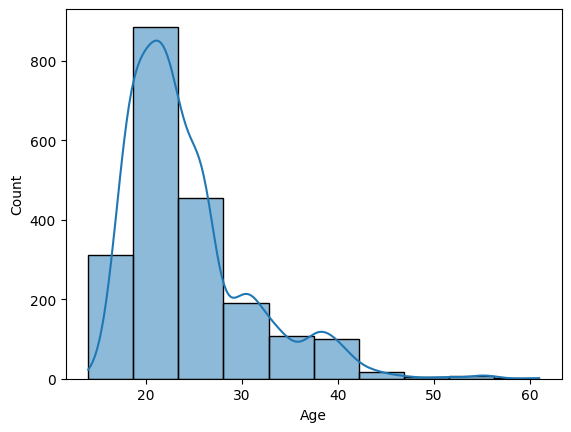

In [ ]:
sns.histplot(obesity.Age, kde=True, bins=10);

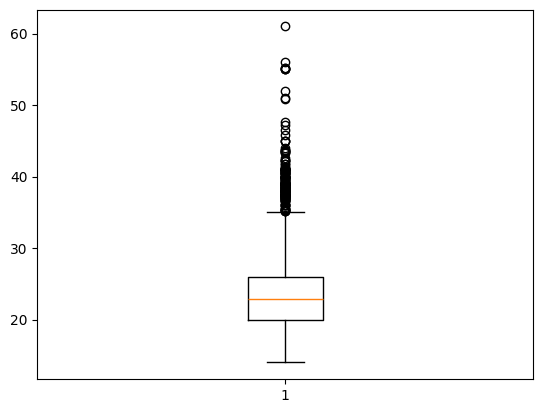

In [ ]:
plt.boxplot(obesity.Age);

In [ ]:
percentiles = obesity.Age.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
print("Percentiles: \n", percentiles)

Percentiles: 
 0.05    17.888409
0.25    19.935311
0.50    22.851747
0.75    26.000000
0.95    38.108430
Name: Age, dtype: float64


How to verify whether every respondent in the dataset has chosen exactly one primary transportation method across those five binary columns? What condition must be true for each row?

In [ ]:
total = 0
transportaion_cols = ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']
for col in transportaion_cols:
  total += obesity[col][obesity[col] == 1].sum()

total_rows = obesity.shape[0]
print(total_rows)
print(total)

2082
2082


In [ ]:
transportaion_cols = ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']
result = obesity[transportaion_cols].sum(axis=1)
print(result.unique())

[1]


In [ ]:
obese_percent = obesity.Obese.value_counts(normalize=True).mul(100)
obese_percent

,proportion
Obese,
0,53.314121
1,46.685879


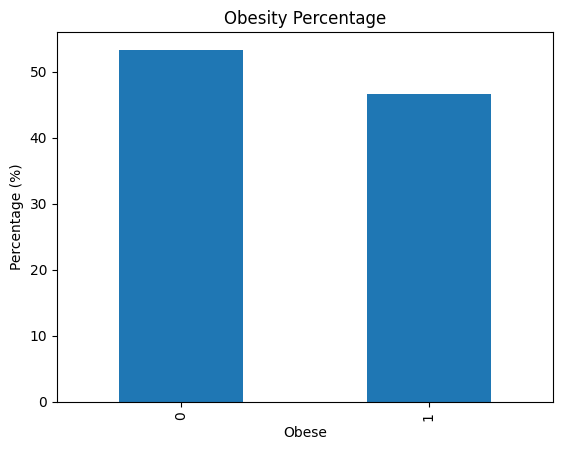

In [ ]:
obese_percent.plot(kind='bar')
plt.ylabel('Percentage (%)')
plt.title('Obesity Percentage');

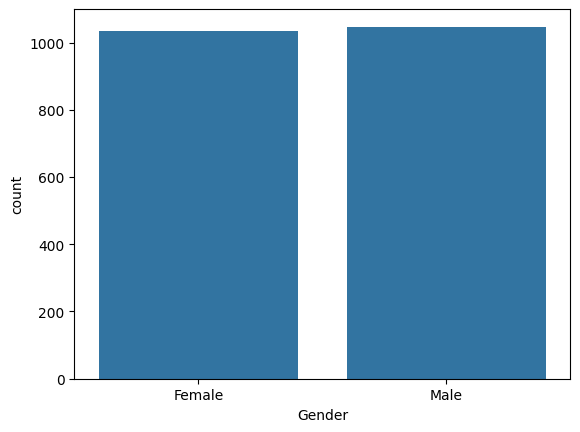

In [ ]:
f,ax = plt.subplots()
sns.countplot(obesity, x='Gender',ax=ax)
ax.set_xticks([0,1], labels=['Female', 'Male']);

#### Bivariate / Question-Driven EDA

Do people with a family history of overweight have a higher obesity rate than those without?

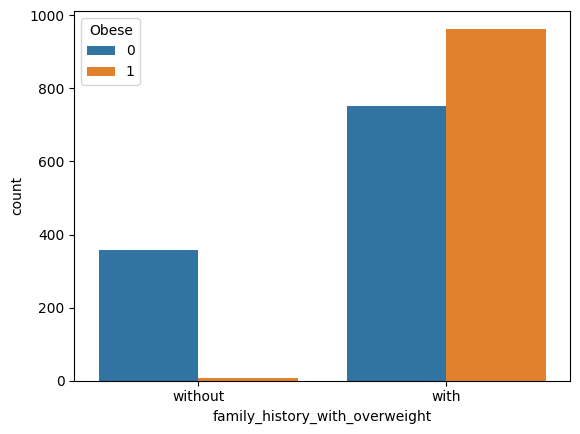

In [ ]:
f,ax = plt.subplots()
sns.countplot(obesity, x='family_history_with_overweight', hue='Obese', ax=ax)
ax.set_xticks([0,1], labels=['without', 'with']);

Do smokers have higher or lower obesity rates than non-smokers?

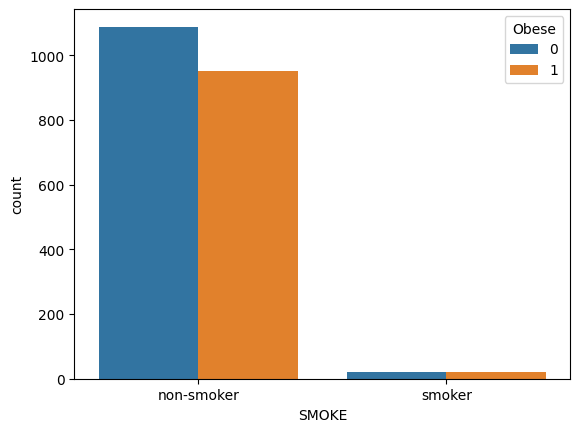

In [ ]:
f,ax = plt.subplots()
sns.countplot(obesity, x='SMOKE', hue='Obese', ax=ax)
ax.set_xticks([0,1], labels=['non-smoker', 'smoker']);

#  1 = smoker, 0 = non-smoker

Does eating high-caloric food frequently (FAVC) associate with higher obesity?

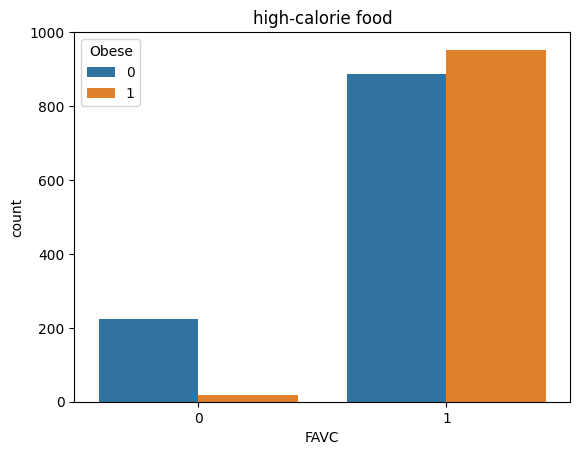

In [ ]:
f,ax = plt.subplots()
sns.countplot(obesity, x='FAVC', hue='Obese', ax=ax)
ax.set_title('high-calorie food');

Does vegetable consumption (FCVC) associate with lower obesity?

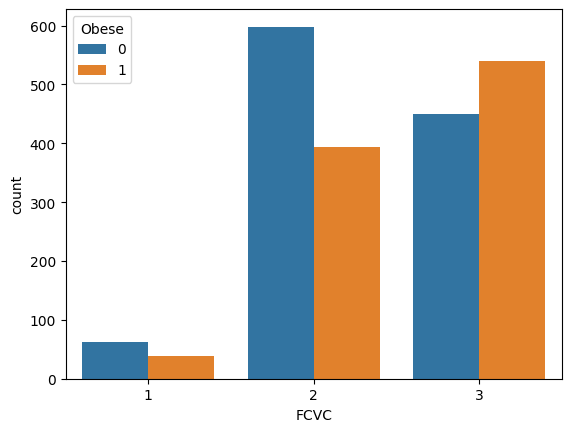

In [ ]:
f,ax = plt.subplots()
sns.countplot(obesity, x='FCVC', hue='Obese', ax=ax)
ax.set_label('Vegetable consumption level')

Does physical activity level (FAF) go down as obesity goes up?

<Axes: xlabel='FAF', ylabel='count'>

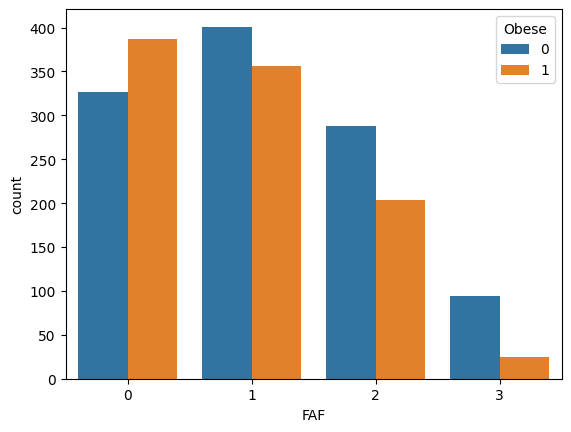

In [ ]:
f,ax = plt.subplots()
sns.countplot(obesity, x='FAF', hue='Obese', ax=ax)

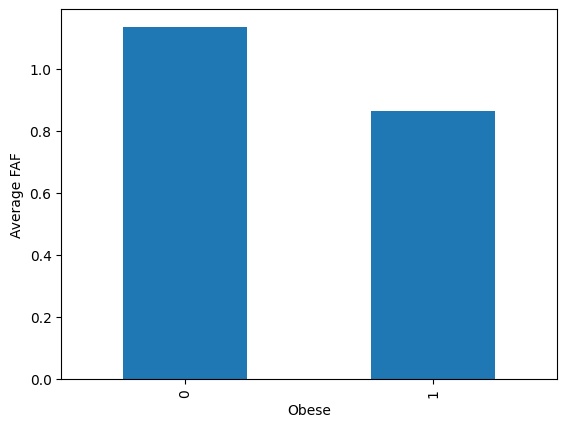

In [ ]:
obesity.groupby('Obese')['FAF'].mean().plot(kind='bar')
plt.ylabel('Average FAF')
plt.show()

<Axes: xlabel='Obese', ylabel='count'>

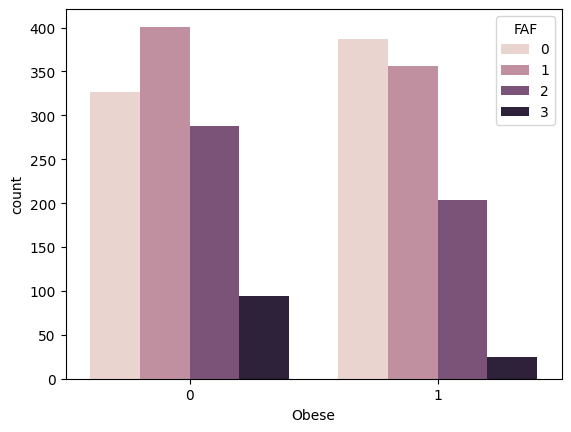

In [ ]:

sns.countplot(data=obesity, x='Obese', hue='FAF')

Does gender associate with obesity rate?

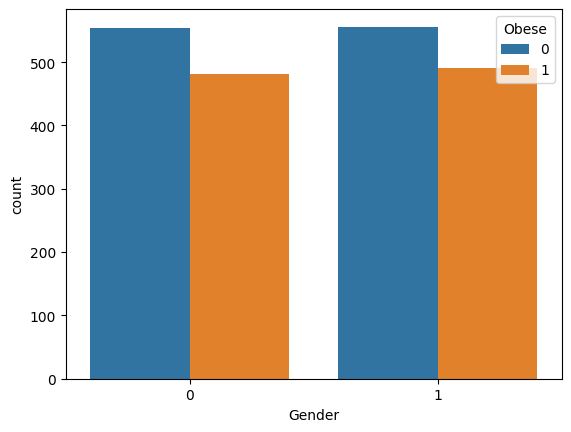

In [ ]:
sns.countplot(obesity, x='Gender', hue='Obese');

Does water intake (CH2O) differ between obese and non-obese groups?

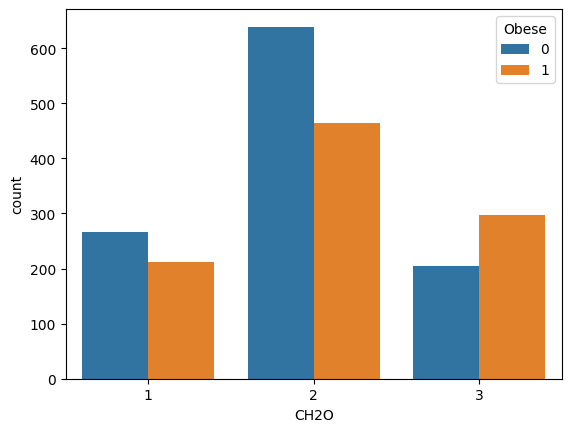

In [ ]:

sns.countplot(data=obesity, x='CH2O', hue='Obese')
plt.show()

Is alcohol consumption (CALC) higher among obese respondents?

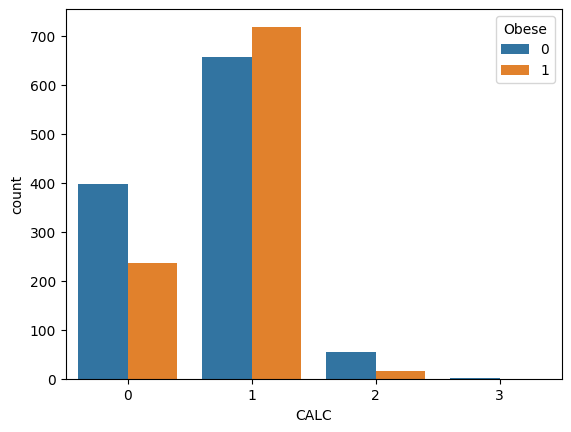

In [ ]:

sns.countplot(data=obesity, x='CALC', hue='Obese')
plt.show()

Do people who monitor their calorie intake (SCC) actually show lower obesity — or does the data suggest self-monitoring alone isn't enough?

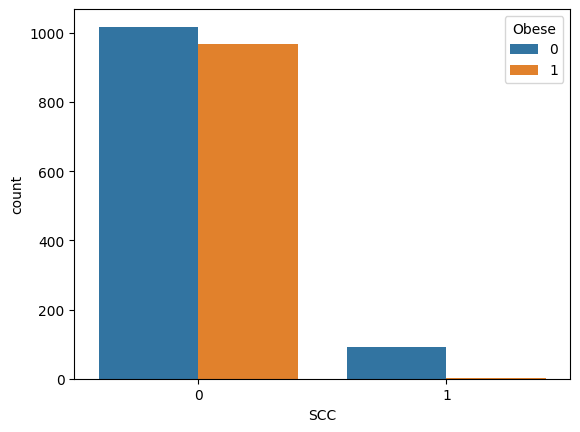

In [ ]:
sns.countplot(data=obesity, x='SCC', hue='Obese');

Comparison of obesity rate across all five modes (Automobile, Bike, Motorbike, Public_Transportation, Walking) side by side. Which mode has the highest/lowest associated obesity rate?

Automobile               45.374449
Bike                     14.285714
Motorbike                27.272727
Public_Transportation    48.810289
Walking                   5.454545
Name: Obese, dtype: float64


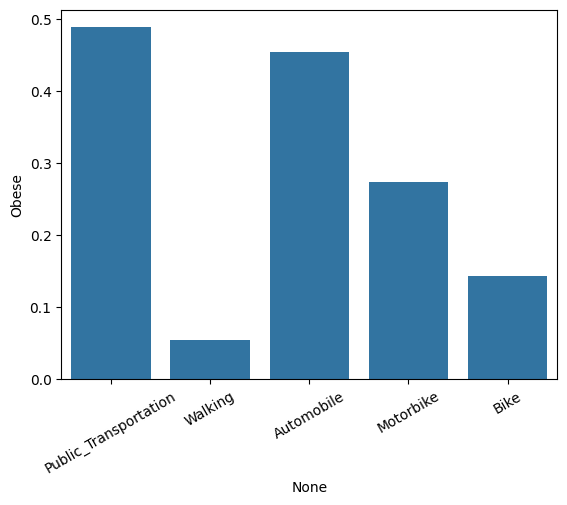

In [ ]:
transport_cols = ['Automobile', 'Bike', 'Motorbike', 'Public_Transportation', 'Walking']

mode = obesity[transport_cols].idxmax(axis=1)
print(obesity.groupby(mode)['Obese'].mean() * 100)

sns.barplot(x=mode, y=obesity['Obese'],errorbar=None)
plt.xticks(rotation=30);

Does obesity risk increase with age? Bin Age into groups (e.g. 18–25, 26–35, 36–50, 50+) and compare obesity rate per bin.

Do people who walk or bike to get around have lower obesity rates than people who drive?

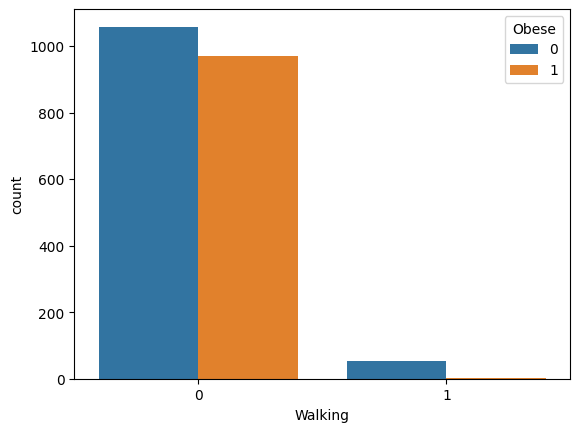

In [ ]:
f,ax = plt.subplots()
sns.countplot(obesity, x='Walking', hue='Obese', ax=ax);

# Walking: 1 = primary transportation mode is walking, 0 = otherwise

In [ ]:
age_group = pd.cut(obesity['Age'], bins=[0, 17, 25, 35, 50, 100], labels=['<18', '18-25', '26-35', '36-50', '50+'])

# obesity rate per age group
print(obesity.groupby(age_group, observed=True)['Obese'].mean() * 100)

# how many people in each group
print(age_group.value_counts().sort_index())


Age
<18       6.666667
18-25    36.640625
26-35    69.686411
36-50    62.025316
50+      10.000000
Name: Obese, dtype: float64
Age
<18        60
18-25    1280
26-35     574
36-50     158
50+        10
Name: count, dtype: int64


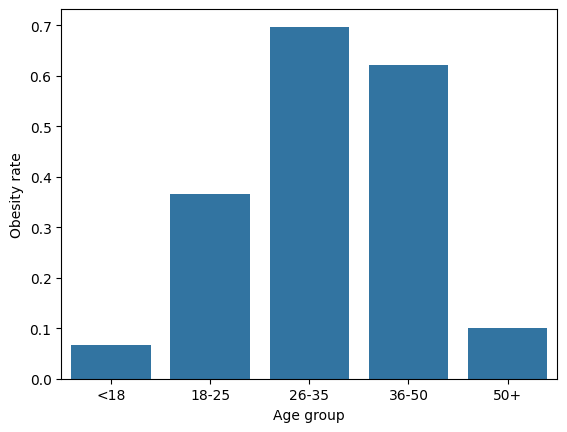

In [ ]:
sns.barplot(x=age_group, y=obesity['Obese'], errorbar=None)
plt.xlabel('Age group')
plt.ylabel('Obesity rate')
plt.show()

#### Multivariate Analysis

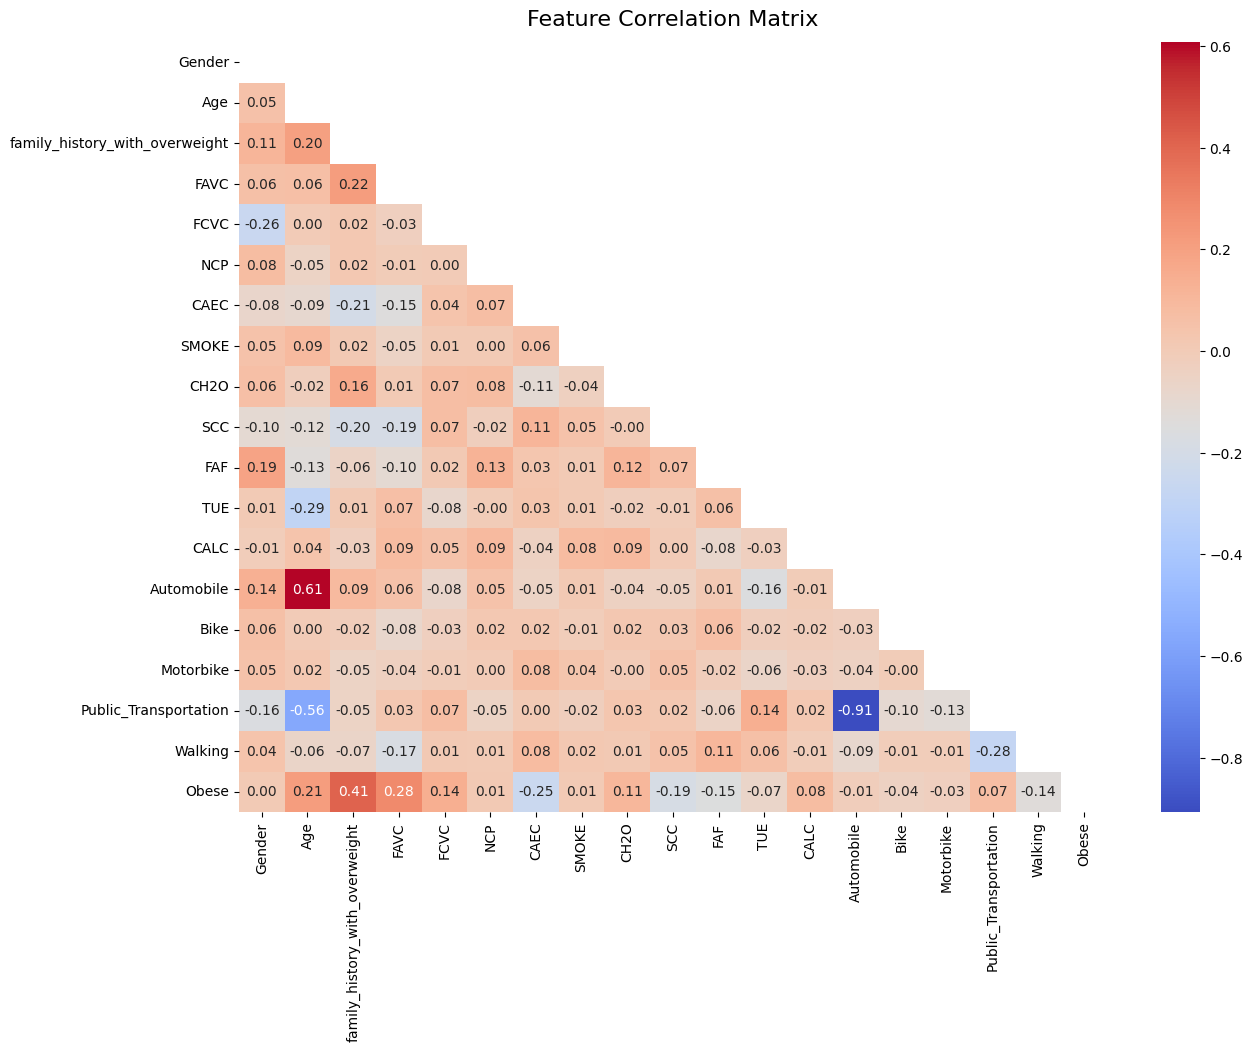

In [ ]:
corr = obesity.corr()
# Create a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(14, 10))

sns.heatmap(corr, mask=mask, cmap='coolwarm', annot=True, fmt='.2f')

plt.title('Feature Correlation Matrix', fontsize=16, pad=12)
plt.show()

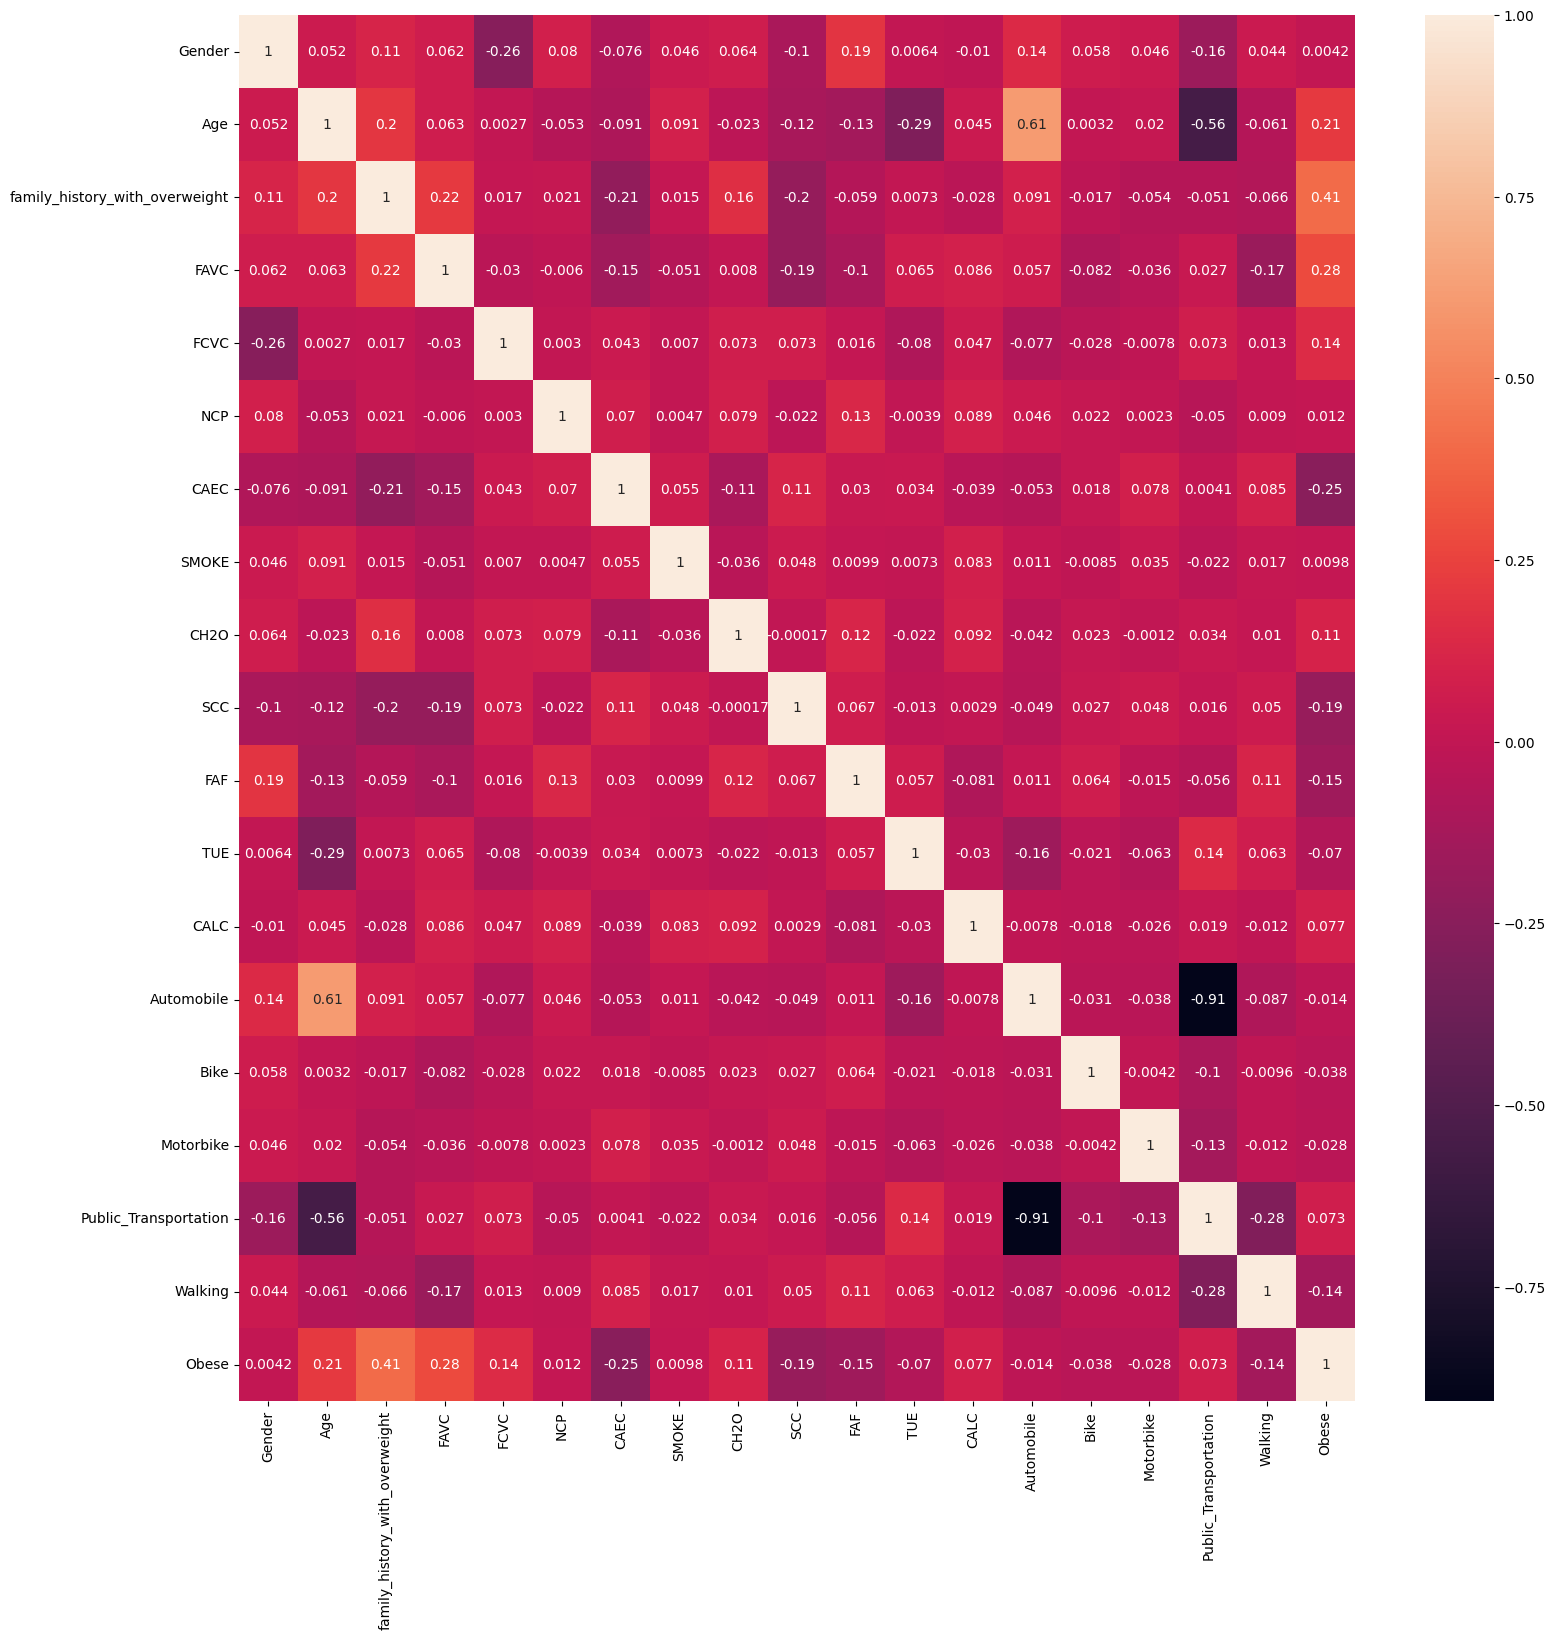

In [ ]:
corr = obesity.corr()
f, ax = plt.subplots(figsize=(18,18))
sns.heatmap(corr, annot=True);

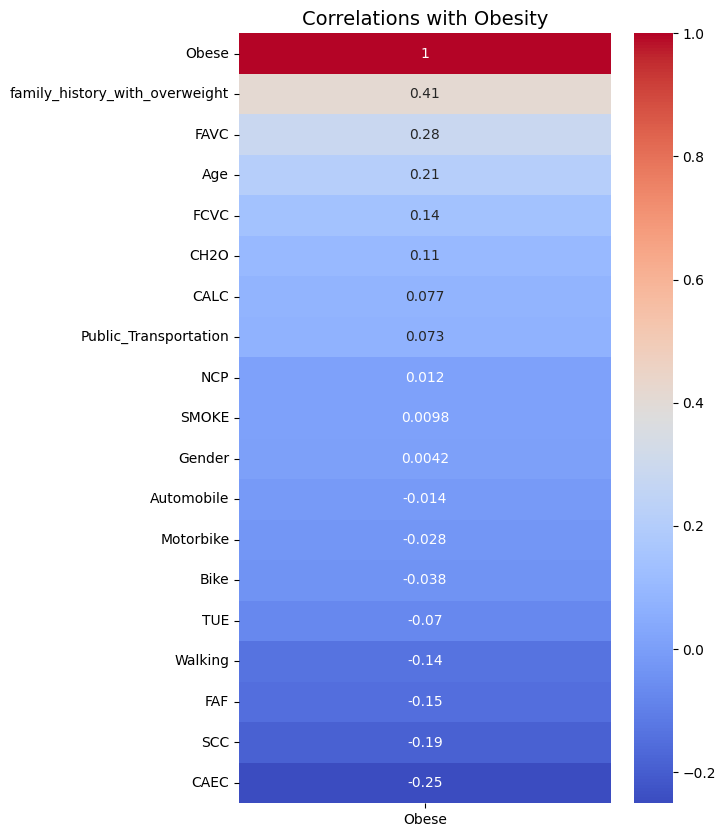

In [ ]:
# Sort correlations specifically relative to 'Obese'
target_corr = obesity.corr()[['Obese']].sort_values(by='Obese', ascending=False)
plt.figure(figsize=(6, 10))
sns.heatmap(target_corr, annot=True,  cmap='coolwarm', )
plt.title('Correlations with Obesity', fontsize=14)
plt.show()

In [ ]:
# obesity.hist(bins=25,figsize=(12,12));

#### Machine Learning

In [ ]:
X = obesity.drop(columns=['Obese'])
y = obesity['Obese']

print(X.shape, y.shape)

(2082, 18) (2082,)


In [ ]:
# Train/test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(1665, 18) (417, 18)
Obese
0    0.533333
1    0.466667
Name: proportion, dtype: float64
Obese
0    0.532374
1    0.467626
Name: proportion, dtype: float64


In [ ]:
# Feature scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_scaled, y_train)
dummy_pred = dummy.predict(X_test_scaled)

print("Baseline accuracy:", accuracy_score(y_test, dummy_pred))

Baseline accuracy: 0.5323741007194245


In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)
log_reg_pred = log_reg.predict(X_test_scaled)

In [ ]:
# Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train_scaled, y_train)
tree_pred = tree.predict(X_test_scaled)

In [ ]:
# Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)
rf_pred = rf.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import classification_report

for name, pred in [('Logistic Regression', log_reg_pred), ('Decision Tree', tree_pred),
                    ('Random Forest', rf_pred)]:
    print(name)
    print(classification_report(y_test, pred))

Logistic Regression
              precision    recall  f1-score   support

           0       0.81      0.63      0.71       222
           1       0.66      0.84      0.74       195

    accuracy                           0.72       417
   macro avg       0.74      0.73      0.72       417
weighted avg       0.74      0.72      0.72       417

Decision Tree
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       222
           1       0.84      0.82      0.83       195

    accuracy                           0.84       417
   macro avg       0.84      0.84      0.84       417
weighted avg       0.84      0.84      0.84       417

Random Forest
              precision    recall  f1-score   support

           0       0.88      0.95      0.91       222
           1       0.93      0.86      0.89       195

    accuracy                           0.90       417
   macro avg       0.91      0.90      0.90       417
weighted avg       0.91   

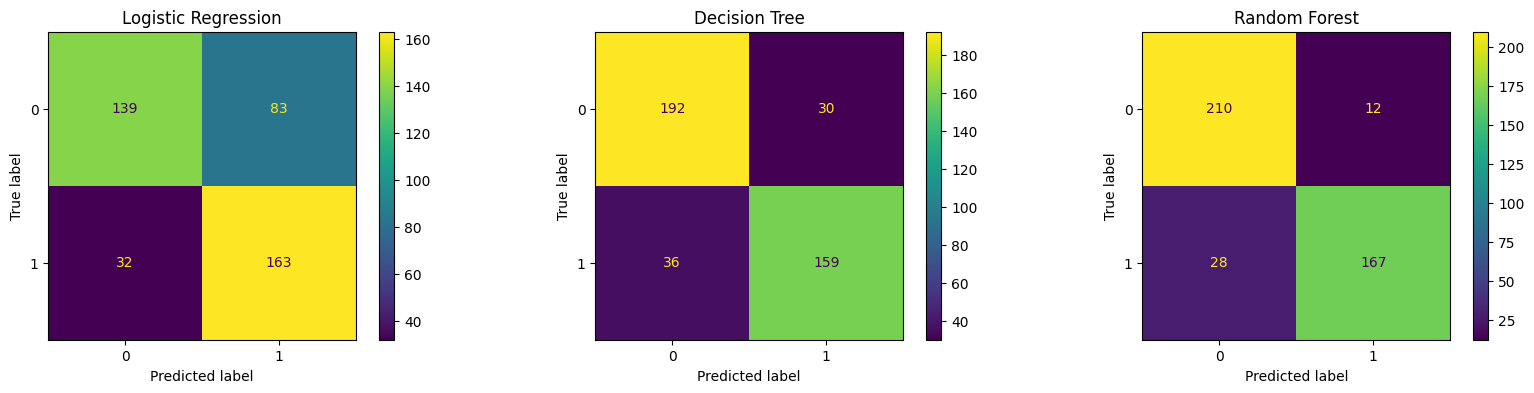

In [ ]:
#  Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, (name, pred) in zip(axes, [('Logistic Regression', log_reg_pred), ('Decision Tree', tree_pred), ('Random Forest', rf_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax)
    ax.set_title(name)
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(rf, X_train_scaled, y_train, cv=5, scoring='f1')
print("Random Forest 5-fold F1 scores:", scores)
print("Mean:", scores.mean())

Random Forest 5-fold F1 scores: [0.90728477 0.89389068 0.89506173 0.90196078 0.91262136]
Mean: 0.9021638630770333


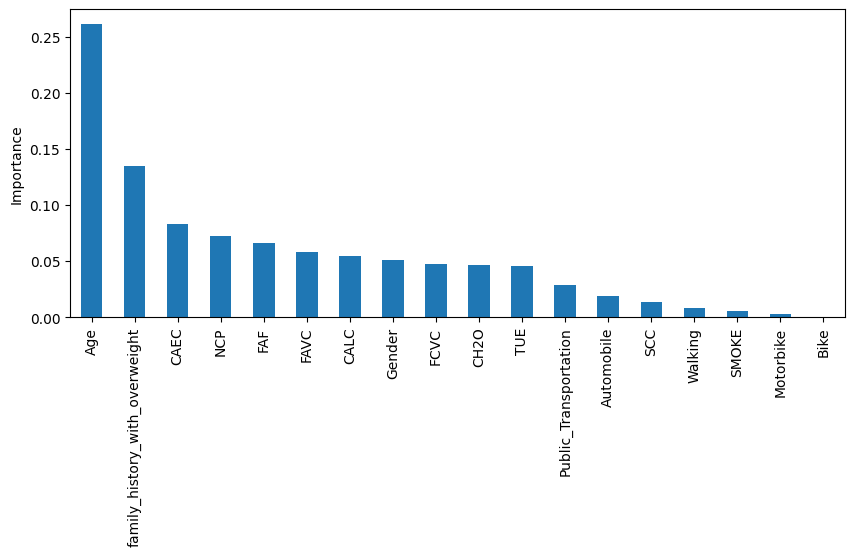

Age                               0.261831
family_history_with_overweight    0.134373
CAEC                              0.083386
NCP                               0.072668
FAF                               0.065833
FAVC                              0.058440
CALC                              0.054919
Gender                            0.050950
FCVC                              0.047680
CH2O                              0.046739
TUE                               0.045710
Public_Transportation             0.028989
Automobile                        0.018352
SCC                               0.013840
Walking                           0.007913
SMOKE                             0.005439
Motorbike                         0.002568
Bike                              0.000370
dtype: float64


In [ ]:
# Feature importance
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.plot(kind='bar', figsize=(10, 4))
plt.ylabel('Importance')
plt.show()

print(importances)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

results = []
for name, model, pred in [('Logistic Regression', log_reg, log_reg_pred), ('Decision Tree', tree, tree_pred),
                           ('Random Forest', rf, rf_pred)]:
    proba = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'AUC': roc_auc_score(y_test, proba)
    })

results_df = pd.DataFrame(results).set_index('Model')
results_df

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Logistic Regression,0.724221,0.662602,0.835897,0.739229,0.822684
Decision Tree,0.841727,0.841270,0.815385,0.828125,0.844560
Random Forest,0.904077,0.932961,0.856410,0.893048,0.967937


Random Forest is the best model on every metric. It also scored a mean F1 of 0.90 across 5-fold cross-validation, close to its single test score of 0.89, so the result is stable and not a lucky split. All three models clearly beat the baseline (53% accuracy), so all of them learned real patterns, but Random Forest learned them best.